In [1]:
uuid_alumno = "ada32e4b-cfde-4fa7-9322-a2f0268b89a0"

# Asistente Inteligente de Extranjería para Autorizaciones de Residencia y Trabajo mediante Gemini, RAG y LangGraph

## Objetivo

Desarrollar un asistente conversacional capaz de responder preguntas relacionadas con procedimientos administrativos de extranjería específicamente autorizaciones de residencia y trabajo en España utilizando exclusivamente la información contenida en la documentación oficial indexada.

El sistema combinará:

- Google Gemini como LLM
- Gemini Embeddings
- ChromaDB como base vectorial
- LangGraph para el agente
- Memoria conversacional
- Retrieval Augmented Generation (RAG)

### Dominio del experto

El agente será especialista únicamente en dos procedimientos oficiales:

- Documento 1

*Hoja Informativa nº12*

Autorización inicial de residencia temporal y trabajo por cuenta ajena.

- Documento 2

*Hoja Informativa nº55*

Modificación desde autorizaciones de residencia temporal que habiliten para trabajar.

## 1.- Carga de Documentos

In [6]:
from langchain_community.document_loaders import PyPDFLoader

loader1 = PyPDFLoader("../data/12. Autorización inicial de residencia temporal y trabajo por cuenta ajena.pdf")
loader2 = PyPDFLoader("../data/55. Modificación desde situaciones de autorizaciones de residencia temporal que habilitan a trabajar.pdf")

docs1 = loader1.load()
docs2 = loader2.load()

documents = docs1 + docs2

print(f"Páginas cargadas: {len(documents)}")

Páginas cargadas: 22


In [3]:
documents

[Document(metadata={'producer': 'Microsoft® Word para Microsoft 365', 'creator': 'Microsoft® Word para Microsoft 365', 'creationdate': '2025-11-05T09:01:55+01:00', 'author': 'REJAS RUBIO, M. TERESA', 'moddate': '2025-11-05T09:01:55+01:00', 'source': '../data/12. Autorización inicial de residencia temporal y trabajo por cuenta ajena.pdf', 'total_pages': 6, 'page': 0, 'page_label': '1'}, page_content='12. Autorización inicial de residencia temporal y \ntrabajo por cuenta ajena  \n*\n El contenido de esta página es meramente orientativo. Únicamente es de aplicación lo \ndispuesto en la normativa vigente en el momento de presentación de la solicitud. \nÚltima actualización:  mayo de 2025 \n \nÍndice de contenidos \n• Tipo de Autorización  \n• Normativa básica \n• Compatibilidad \n• Requisitos \n• Documentación exigible  \n• Procedimiento  \n \nTIPO DE AUTORIZACIÓN \nEs una autorización de residencia temporal y trabajo por cuenta ajena que solicita un \nempleador o empresario para la contra

## 2.- Dividir en Chunks

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    separators=["\n\n", "\n", ".", " "]
)

chunks = text_splitter.split_documents(documents)

print(f"Chunks generados: {len(chunks)}")

Chunks generados: 62


In [7]:
# Ejemplo
print(chunks[0].page_content)

12. Autorización inicial de residencia temporal y 
trabajo por cuenta ajena  
*
 El contenido de esta página es meramente orientativo. Únicamente es de aplicación lo 
dispuesto en la normativa vigente en el momento de presentación de la solicitud. 
Última actualización:  mayo de 2025 
 
Índice de contenidos 
• Tipo de Autorización  
• Normativa básica 
• Compatibilidad 
• Requisitos 
• Documentación exigible  
• Procedimiento  
 
TIPO DE AUTORIZACIÓN 
Es una autorización de residencia temporal y trabajo por cuenta ajena que solicita un 
empleador o empresario para la contratación de un a persona trabajadora extranjera 
mayor de 16 años por un periodo superior a noventa días e inferior a cinco años.  
 
NORMATIVA BÁSICA 
• Ley Orgánica 4/2000, de 11 de enero , sobre derechos y libertades de los 
extranjeros en España y su integración social (artículos 36, 38 y 40). 
• Real Decreto 1155/2024, de 19 de noviembre , por el que se aprueba el


## 3.- Crear embeddings con Gemini

In [8]:
import os
from dotenv import load_dotenv

load_dotenv()

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

In [9]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embeddings = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001",
    google_api_key=GEMINI_API_KEY
)

## 4.- Crear la Base Vectorial (ChromaDB)

In [10]:
from langchain_chroma import Chroma

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    persist_directory="../chroma_db"
)

print("Base vectorial creada correctamente.")

Base vectorial creada correctamente.


## 5.- Crear el Retriever

In [11]:
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={
        "k":4
    }
)

In [12]:
# Prueba
query = "¿Quién presenta la solicitud?"

results = retriever.invoke(query)

for i, doc in enumerate(results):
    print(f"\nDocumento {i+1}")
    print(doc.page_content[:500])


Documento 1
Internacional. 
Información sobre traducción y legalización de los documentos. 
 
Procedimiento 
• Sujeto legitimado para presentar la solicitud: la persona extranjera o, en su caso, 
el empleador, personalmente, o a través de un sujeto legitimado que tenga atribuida 
la representación legal empresarial. 
 
Hoja informativa sobre sujetos legitimados. 
 
• Lugar de presentación: 
 
o Presencialmente, en la Oficina de Extranjería de la provincia en la que la 
persona extranjera tenga establecida o

Documento 2
Internacional. 
Información sobre traducción y legalización de los documentos. 
 
Procedimiento 
• Sujeto legitimado para presentar la solicitud: la persona extranjera o, en su caso, 
el empleador, personalmente, o a través de un sujeto legitimado que tenga atribuida 
la representación legal empresarial. 
 
Hoja informativa sobre sujetos legitimados. 
 
• Lugar de presentación: 
 
o Presencialmente, en la Oficina de Extranjería de la provincia en la que la 
persona ext

## 6.- Crear el LLM Gemini

In [13]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0,
    google_api_key=GEMINI_API_KEY
)

## 7.- Crear el Prompt

In [14]:
from langchain_core.prompts import ChatPromptTemplate

system_prompt = """
Eres un experto en procedimientos de Extranjería en España.

Solo puedes responder utilizando la información proporcionada por los documentos recuperados.

Los documentos pertenecen exclusivamente a:

- Hoja Informativa nº12. Autorización inicial de residencia temporal y trabajo por cuenta ajena.
- Hoja Informativa nº55. Modificación desde situaciones de autorizaciones de residencia temporal que habilitan a trabajar.

Nunca inventes información.

Si no encuentras la respuesta en el contexto, responde:

"No dispongo de información suficiente en la documentación proporcionada."

Responde de forma clara y estructurada.
"""

prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system_prompt),
        ("human",
"""
Contexto:

{context}

Pregunta:

{question}
""")
    ]
)

## 8.- Crear la cadena RAG

In [15]:
from langchain_core.output_parsers import StrOutputParser

parser = StrOutputParser()

rag_chain = prompt | llm | parser

## 9.- Crear memoria con LangGraph

In [16]:
from typing import Annotated

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

from langchain_core.messages import (
    HumanMessage,
    AIMessage,
    SystemMessage
)

from typing_extensions import TypedDict
from langchain_core.documents import Document

In [17]:
# Estado
class State(TypedDict):

    messages: Annotated[list, add_messages]

    context: list[Document]

In [21]:
# Nodo Retrieve
def retrieve_documents(state: State):
    """
    Recupera los documentos más relevantes de la base vectorial a partir de
    la última pregunta realizada por el usuario.

    Esta función representa el nodo de recuperación (Retrieval) del flujo RAG.
    Extrae el último mensaje de la conversación, realiza una búsqueda por
    similitud en ChromaDB mediante el retriever y devuelve los documentos
    recuperados para que puedan utilizarse posteriormente en la generación
    de la respuesta.

    Parameters
    ----------
    state : State
        Estado actual del grafo de LangGraph. Debe contener el historial de
        mensajes de la conversación.

    Returns
    -------
    dict
        Diccionario con la clave ``context`` que contiene la lista de
        documentos recuperados de la base vectorial.

    """
    question = state["messages"][-1].content

    docs = retriever.invoke(question)

    return {
        "context": docs
    }

In [22]:
# Nodo Generate
def generate_response(state: State):
    """
    Genera la respuesta del asistente utilizando la información recuperada
    por el nodo de recuperación y el modelo Gemini.

    La función construye el contexto a partir de los documentos recuperados,
    obtiene la última pregunta del usuario y ejecuta la cadena RAG
    (Prompt → Gemini → Parser) para producir una respuesta fundamentada en
    la documentación disponible.

    Parameters
    ----------
    state : State
        Estado actual del grafo. Debe contener el historial de mensajes y los
        documentos recuperados en el nodo anterior.

    Returns
    -------
    dict
        Diccionario con la clave ``messages`` que contiene el mensaje generado
        por el modelo de lenguaje en formato ``AIMessage``.

    """
    docs = state["context"]

    context = "\n\n".join(
        doc.page_content
        for doc in docs
    )

    question = state["messages"][-1].content

    answer = rag_chain.invoke(
        {
            "context": context,
            "question": question
        }
    )

    return {
        "messages": [
            AIMessage(content=answer)
        ]
    }

In [23]:
# Nodo Memory
def update_memory(state):
    """
    Nodo final del flujo encargado de cerrar la ejecución del agente.

    La persistencia del historial conversacional es gestionada automáticamente
    por ``MemorySaver`` mediante el checkpointer de LangGraph, por lo que esta
    función no realiza ninguna modificación sobre el estado.

    Se mantiene como un nodo independiente para representar de forma explícita
    la etapa de memoria dentro del flujo del agente y facilitar futuras
    ampliaciones, como el registro de conversaciones, auditorías o métricas.

    Parameters
    ----------
    state : State
        Estado actual del grafo tras la generación de la respuesta.

    Returns
    -------
    dict
        Diccionario vacío, ya que no se modifica el estado.

    """
    return {}

In [24]:
# Construcción del Grafo
builder = StateGraph(State)

builder.add_node("retrieve", retrieve_documents)
builder.add_node("generate", generate_response)
builder.add_node("memory", update_memory)

builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", "memory")
builder.add_edge("memory", END)

memory = MemorySaver()

graph = builder.compile(
    checkpointer=memory
)

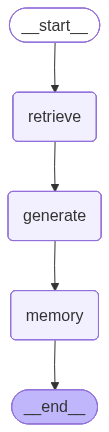

In [25]:
# Visualización
from IPython.display import Image, display

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

## 10.- Conversación con Memoria

In [26]:
config = {
    "configurable": {
        "thread_id":"usuario1"
    }
}

In [30]:
# Pregunta 1
response = graph.invoke(

    {
        "messages":[
            HumanMessage(
                content="¿Cuánto demoran en dar la respuesta de la resolución?"
            )
        ]
    },

    config=config
)

print(response["messages"][-1].content)

El plazo de resolución de la solicitud es de tres meses, contados a partir del día siguiente a la fecha en que haya tenido entrada en el registro del órgano competente para su tramitación.


In [28]:
# Pregunta 2
response = graph.invoke(

    {
        "messages":[
            HumanMessage(
                content="Estoy trabajando con una autorización temporal. ¿Cuándo puedo solicitar la modificación?"
            )
        ]
    },

    config=config
)

print(response["messages"][-1].content)

Según la documentación proporcionada, el plazo de solicitud para la modificación desde una autorización para actividades de temporada es:

*   Tres meses anteriores a la finalización del periodo de vigencia de la autorización.
*   O, una vez retornado al país de origen o procedencia tras haber finalizado dicho periodo, dentro de los seis meses posteriores a su finalización.


In [29]:
# Pregunta 3 / Memoria Conversacional
response = graph.invoke(

    {
        "messages":[
            HumanMessage(
                content="Antes me dijiste cuál era el plazo de resolución. ¿Qué ocurre si ese plazo finaliza sin respuesta?"
            )
        ]
    },

    config=config
)

print(response["messages"][-1].content)

El plazo de resolución de la solicitud es de tres meses.

Si transcurre dicho plazo sin que la Administración haya practicado la notificación, se podrá entender que la solicitud ha sido desestimada por silencio administrativo.


## 11.- Chat Interactivo

In [31]:
from langchain_core.messages import HumanMessage

def chatear(app, mensaje: str, thread_id: str):
    """
    Envía un mensaje al agente utilizando un thread determinado.

    Parameters
    ----------
    app : LangGraph App
    mensaje : str
        Pregunta del usuario.
    thread_id : str
        Identificador de la conversación.

    Returns
    -------
    str
        Respuesta del asistente.
    """

    config = {
        "configurable": {
            "thread_id": thread_id
        }
    }

    estado_entrada = {
        "messages": [
            HumanMessage(content=mensaje)
        ]
    }

    resultado = app.invoke(
        estado_entrada,
        config=config
    )

    return resultado["messages"][-1].content

print("✅ Función de chat lista")

✅ Función de chat lista


In [32]:
# Conversación 1
r1 = chatear(
    graph,
    "Hola, quiero solicitar una autorización inicial de residencia y trabajo.",
    "usuario001"
)

print(r1)

La autorización inicial de residencia temporal y trabajo por cuenta ajena es un tipo de autorización que:

*   **Solicitante:** La solicita un empleador o empresario.
*   **Objeto:** Para la contratación de una persona trabajadora extranjera.
*   **Edad del trabajador:** La persona trabajadora debe ser mayor de 16 años.
*   **Duración:** Por un periodo superior a noventa días e inferior a cinco años.


In [33]:
# Usa memoria
r2 = chatear(
    graph,
    "¿Qué documentación necesito?",
    "usuario001"
)

print(r2)

Según la documentación proporcionada, la documentación exigible es la siguiente:

**Documentación general:**
*   Impreso de solicitud en modelo oficial (EX – 03), debidamente cumplimentado y firmado por la empresa que contrata.
*   Con carácter general, se deberán aportar copias de los documentos y exhibir los originales en el momento de presentar la solicitud.

**Documentación referida al trabajador:**
*   Copia completa del pasaporte o documento de viaje en vigor.
*   Copia de la documentación que acredite poseer la capacitación y, en su caso, la cualificación profesional legalmente exigida para el ejercicio de la profesión, en su caso debidamente homologada.

**Documentación referida a la empresa (excepto servicio doméstico):**
*   Documentación que identifique a la empresa que solicita la autorización:
    *   Si se trata de un empresario individual: copia del NIF o NIE, o consentimiento.


In [37]:
r3 = chatear(
    graph,
    "¿Qué tasas debo pagar?",
    "usuario001"
)

print(r3)

Debes pagar las siguientes tasas:

1.  **Modelo 790 código 052, epígrafe 2.1.3.** "autorización inicial de residencia temporal y trabajo por cuenta ajena y/o propia". Esta tasa debe ser abonada por la persona trabajadora extranjera.
2.  **Modelo 790 código 062, epígrafe 3.2.1.** "autorización de trabajo para autorizaciones iniciales de residencia temporal de trabajo por cuenta ajena". Esta tasa debe ser abonada por el empleador, si la autorización de trabajo tiene una duración igual o superior a seis meses.

Las tasas se devengarán en el momento de presentación de la solicitud y deberán abonarse en el plazo de diez días hábiles. El impreso para el abono se podrá descargar desde la página correspondiente.


In [38]:
r4 = chatear(
    graph,
    "¿Qué ocurre si me deniegan la autorización?",
    "usuario001"
)

print(r4)

No dispongo de información suficiente en la documentación proporcionada.


In [36]:
r5 = chatear(
    graph,
    "¿Qué documentos debe aportar el empleador?",
    "usuario001"
)

print(r5)

El empleador debe aportar los siguientes documentos:

*   Número de identificación fiscal y, en el caso de que la empresa esté constituida como persona jurídica, documento público que otorgue su representación legal en favor de la persona que formule la solicitud. Si el empleador fuera persona física, no se le exigirá la presentación del número de identificación fiscal si accede a la verificación de sus datos a través del Sistema de Verificación de Datos de Identidad.
*   Copia del contrato de trabajo, en modelo oficial establecido.
*   Documentos acreditativos de los medios económicos, materiales o personales de los que dispone el empleador para su proyecto empresarial y para hacer frente a las obligaciones derivadas del contrato firmado con la persona trabajadora extranjera.
*   Documentación que acredite la capacitación y, en su caso, la cualificación profesional legalmente exigida para el ejercicio de la profesión.
*   En su caso, certificado del Servicio Público de Empleo competen